# Лабораторная работа № 17. Свёрточная нейронная сеть
**Дисциплина:** Методы искусственного интеллекта  
**Студент:** Мальцев Николай Артемович  
**Группа:** ИНС-м-о-25-2

**Цель:** получение практических навыков по реализации пайплайна для решения задачи машинного обучения с использованием свёрточной нейросетевой модели.

**Задачи:** выбрать данные и архитектуру CNN; спроектировать сеть из блоков; обучить и настроить её; изучить потери и градиенты; сохранить и повторно загрузить модель.

**Данные:** KolektorSDD2: настоящие цветные изображения промышленного контроля поверхностей.

Работа выполнена по методичке *Practicum_AI_Methods.pdf*, с. 156–160. В цели исправлены только опечатки.

## 1. Локальный запуск и основные понятия
Используем прежнее окружение `rcaeval-ai` с PyTorch на CPU. Новые библиотеки устанавливать не нужно. В VS Code выбираем его ядро и выполняем **Run All**. Ноутбук не требует выполнения предыдущих работ.

Эпоха — проход по всему обучению, мини-батч — небольшая порция изображений. Модель учится по обучению; отдельная часть подбора нужна для выбора настроек и весов. Итоговый тест просматриваем после выбора. Accuracy — доля правильных ответов.

Подключаем библиотеки для файлов, таблиц и графиков.

In [1]:
from pathlib import Path
from urllib.request import urlopen, urlretrieve
from importlib.metadata import version
import copy
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

Подключаем PyTorch и методы оценки.

In [2]:
import zipfile
from PIL import Image
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score, roc_auc_score, confusion_matrix, precision_recall_curve)

Задаём пути и воспроизводимые настройки.

In [3]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'environment.yml').is_file() and (p / 'notebooks').is_dir())
REPORT = ROOT / 'reports/lab17'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 17
torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
sns.set_theme(style='whitegrid')

Печатаем и сохраняем версии библиотек.

In [4]:
versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'torch', 'Pillow']})
display(pd.Series(versions, name='Версия'))
(REPORT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

Python          3.11.17
numpy             2.2.6
pandas            2.3.3
matplotlib       3.10.9
scikit-learn      1.7.2
torch            2.14.1
Pillow           12.3.0
Name: Версия, dtype: object

162

Определяем сохранение и показ рисунков.

In [5]:
def save_show(fig, filename):
    fig.savefig(FIGURES / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

MLP разворачивает изображение в строку. CNN сначала ищет небольшие местные узоры: края, линии, пятна. Один свёрточный фильтр применяется по всему изображению и использует одни и те же веса. Pooling уменьшает карту, а полносвязный выход принимает решение по найденным признакам.

Градиент показывает, как изменение веса влияет на потери. Изучаем его норму — общую величину градиентов. Она не равна ошибке классификации; слишком маленькие или большие значения могут подсказать проблему обучения.

## 2. Выбор данных и учебный пример CNN
### 2.1. Почему KolektorSDD2
В № 17 нет отдельного готового листинга учебной задачи: методичка просит самостоятельно выбрать изображения, построить и обучить CNN. Сначала разбираем небольшой пример прямого прохода через блоки, затем выполняем все индивидуальные пункты на выбранном наборе.

Табличный RCAEval для обычной двумерной CNN не подходит без искусственного превращения метрик в картинки. Используем **KolektorSDD2**, а не небольшой KolektorSDD из № 12: здесь больше примеров и есть готовый тест авторов. Это мониторинг дефектов производственных поверхностей, а не Kubernetes.

В наборе 3335 снимков: 356 с дефектом и 2979 без него. У авторов обучение содержит 2331 снимок (246 дефектных), тест — 1004 (110 дефектных). Маска нужна только для ответа «есть дефект»; пиксели маски никогда не становятся входом CNN. Мы выполняем классификацию целого изображения, а не сегментацию трещины.

Источник — ViCoS Lab. Авторы: Jakob Božič, Domen Tabernik, Danijel Skočaj; *Mixed supervision for surface-defect detection: from weakly to fully supervised learning*, 2021. Лицензия CC BY-NC-SA 4.0.

**Согласование датасета с преподавателем:** ____________________  
**Дата:** ____________________

Получаем официальный архив только при отсутствии локальной копии.

In [6]:
DATA = ROOT / 'data/raw/kolektor2'
DATA.mkdir(parents=True, exist_ok=True)
archive_path = DATA / 'KolektorSDD2.zip'
image_root = DATA / 'images'
source_url = 'https://data.vicos.si/datasets/KSDD/KolektorSDD2.zip'
if not archive_path.exists():
    urlretrieve(source_url, archive_path)
if not image_root.exists():
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(image_root)

Архив примерно 853 МБ скачивается один раз. Дальше используется локальная копия. В архиве есть две служебные копии файлов с пометкой `(copy)`; выбираем только изображения с числовым именем. Вход — настоящая цветная картинка. Разметка и файлы с другими именами не включаются в признаки.

Читаем снимки, уменьшаем их и получаем метки по маскам.

In [7]:
IMAGE_SIZE = (64, 176)
image_rows, image_arrays = [], []
for split in ['train', 'test']:
    paths = sorted(p for p in (image_root / split).glob('*.png') if p.stem.isdecimal())
    for path in paths:
        with Image.open(path) as original:
            image = original.convert('RGB')
            resized = image.resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
            image_arrays.append(np.asarray(resized).copy())
            width, height = image.size
        mask_path = path.with_name(path.stem + '_GT.png')
        with Image.open(mask_path) as mask:
            defect = int(np.asarray(mask.convert('L')).max() > 0)
        image_rows.append({'file': str(path.relative_to(image_root)), 'source_split': split,
                           'width': width, 'height': height, 'defect': defect})
image_info = pd.DataFrame(image_rows)
images = np.stack(image_arrays)
labels = image_info.defect.to_numpy(dtype=np.int64)

Показываем структуру и соотношение классов.

In [8]:
display(image_info.head())
display(pd.crosstab(image_info.source_split, image_info.defect).rename(columns={0: 'Без дефекта', 1: 'Дефект'}))
print('Изображения:', images.shape, images.dtype)
print('Исходные размеры:', image_info[['width', 'height']].drop_duplicates().to_dict('records'))

,file,source_split,width,height,defect
0,train/10000.png,train,229,645,0
1,train/10001.png,train,228,633,0
2,train/10002.png,train,230,647,0
3,train/10003.png,train,229,634,0
4,train/10004.png,train,228,632,0


defect,Без дефекта,Дефект
source_split,,
test,894,110
train,2085,246


Изображения: (3335, 176, 64, 3) uint8
Исходные размеры: [{'width': 229, 'height': 645}, {'width': 228, 'height': 633}, {'width': 230, 'height': 647}, {'width': 229, 'height': 634}, {'width': 228, 'height': 632}, {'width': 230, 'height': 628}, {'width': 233, 'height': 642}, {'width': 229, 'height': 640}, {'width': 228, 'height': 634}, {'width': 231, 'height': 643}, {'width': 229, 'height': 635}, {'width': 230, 'height': 638}, {'width': 230, 'height': 639}, {'width': 229, 'height': 642}, {'width': 229, 'height': 646}, {'width': 230, 'height': 636}, {'width': 231, 'height': 645}, {'width': 230, 'height': 643}, {'width': 233, 'height': 626}, {'width': 228, 'height': 649}, {'width': 230, 'height': 637}, {'width': 230, 'height': 652}, {'width': 228, 'height': 636}, {'width': 229, 'height': 643}, {'width': 229, 'height': 637}, {'width': 229, 'height': 629}, {'width': 232, 'height': 637}, {'width': 228, 'height': 646}, {'width': 230, 'height': 633}, {'width': 229, 'height': 626}, {'width': 231

Для локального CPU снимки приведены к 64×176 с примерно сохранёнными пропорциями. Цвет оставлен: у некоторых дефектов отличается оттенок. При уменьшении мелкие детали могут потеряться — качество относится к этому размеру, а не к максимальным возможностям полноразмерных снимков. Нормировка на 255 использует известный диапазон яркости и не обучается по тесту.

Показываем оригиналы с дефектом и без него.

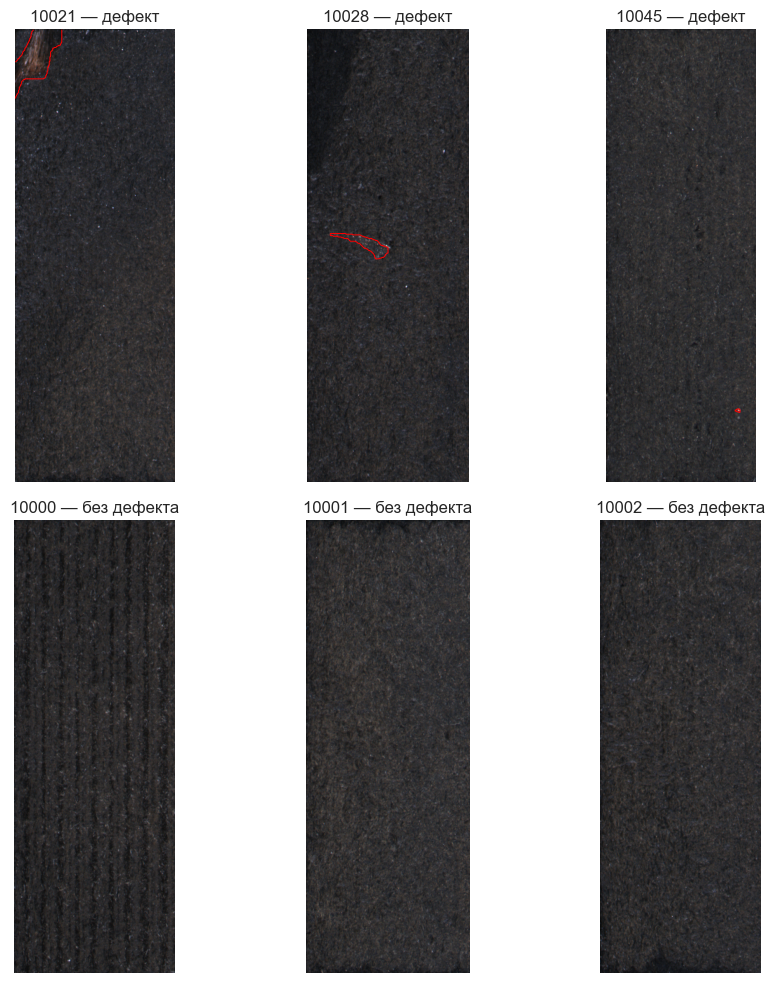

In [9]:
example_indices = np.r_[np.flatnonzero(labels == 1)[:3], np.flatnonzero(labels == 0)[:3]]
fig, axes = plt.subplots(2, 3, figsize=(10, 10))
for ax, index in zip(axes.flat, example_indices):
    path = image_root / image_info.iloc[index].file
    image = np.asarray(Image.open(path).convert('RGB'))
    ax.imshow(image)
    if labels[index]:
        mask = np.asarray(Image.open(path.with_name(path.stem + '_GT.png')).convert('L'))
        ax.contour(mask > 0, levels=[0.5], colors='red', linewidths=0.7)
    ax.set_title(path.stem + (' — дефект' if labels[index] else ' — без дефекта'))
    ax.axis('off')
fig.tight_layout()
save_show(fig, '01_surface_examples.png')

Каждая панель — настоящий снимок. Красный контур только показывает исходную разметку дефекта для просмотра; в сеть передаётся картинка без контура и маски. Пятно или царапина могут занимать малую часть поверхности, поэтому задача сложнее простой проверки общей яркости.

Сохраняем тест авторов и отделяем часть подбора только от их обучения.

In [10]:
develop_idx = np.flatnonzero(image_info.source_split.to_numpy() == 'train')
test_idx = np.flatnonzero(image_info.source_split.to_numpy() == 'test')
train_idx, valid_idx = train_test_split(develop_idx, test_size=0.2, stratify=labels[develop_idx], random_state=SEED)
image_tensor = torch.from_numpy(images).permute(0, 3, 1, 2)
label_tensor = torch.as_tensor(labels, dtype=torch.float32)
train_data = TensorDataset(image_tensor[train_idx], label_tensor[train_idx])
valid_data = TensorDataset(image_tensor[valid_idx], label_tensor[valid_idx])
test_data = TensorDataset(image_tensor[test_idx], label_tensor[test_idx])
print('Обучение / подбор / тест:', len(train_data), len(valid_data), len(test_data))

Обучение / подбор / тест: 1864 467 1004


Готовый тест авторов не перемешиваем с обучением. Из их обучения выделяем 20% для выбора параметров и порога. Полей с идентификатором изделия в этом архиве нет, поэтому дополнительное разделение по изделиям не приписываем. Вход PyTorch имеет порядок N×C×H×W: для нашего снимка это 3×176×64.

### 2.2. Проектируем CNN из блоков — пункт 2
Два блока: Conv2d с ядром 3×3 и отступом 1 → ReLU → MaxPool2d 2×2. Затем AdaptiveMaxPool2d 2×2 оставляет сильные местные отклики; полносвязный слой и один выход оценивают наличие дефекта. Dropout уменьшает запоминание отдельных признаков.

В Conv2d stride=1 и padding=1 сохраняют высоту и ширину. Каждый MaxPool2d уменьшает их вдвое: 176×64 → 88×32 → 44×16. Входу Flatten соответствует channels₂×2×2 чисел.

Определяем небольшую CNN из стандартных блоков PyTorch.

In [11]:
def make_cnn(channels=(8, 16), dropout=0.25):
    first, second = channels
    return nn.Sequential(
        nn.Conv2d(3, first, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(first, second, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.AdaptiveMaxPool2d((2, 2)), nn.Flatten(),
        nn.Linear(second * 4, 32), nn.ReLU(), nn.Dropout(dropout), nn.Linear(32, 1)
    )

Выполняем учебный прямой проход и показываем размеры после каждого слоя.

In [12]:
torch.manual_seed(SEED)
example_network = make_cnn()
example_network.eval()
example_input = image_tensor[train_idx[:2]].float() / 255
shape_rows = [{'layer': 'Вход', 'shape': tuple(example_input.shape)}]
with torch.no_grad():
    output = example_input
    for layer in example_network:
        output = layer(output)
        shape_rows.append({'layer': layer.__class__.__name__, 'shape': tuple(output.shape)})
display(pd.DataFrame(shape_rows))
print('Обучаемых параметров:', sum(p.numel() for p in example_network.parameters()))

,layer,shape
0,Вход,"(2, 3, 176, 64)"
1,Conv2d,"(2, 8, 176, 64)"
2,ReLU,"(2, 8, 176, 64)"
3,MaxPool2d,"(2, 8, 88, 32)"
4,Conv2d,"(2, 16, 88, 32)"
5,ReLU,"(2, 16, 88, 32)"
6,MaxPool2d,"(2, 16, 44, 16)"
7,AdaptiveMaxPool2d,"(2, 16, 2, 2)"
8,Flatten,"(2, 64)"
9,Linear,"(2, 32)"


Обучаемых параметров: 3505


В этом примере веса ещё не обучены. Таблица показывает только движение двух реальных снимков через блоки. В конце получается одно число на снимок — logit. При вычислении вероятности применяем sigmoid; при обучении BCEWithLogitsLoss делает нужное преобразование сама.

## 3. Индивидуальное задание: обучение и оценка
### 3.1. Учитываем редкие дефекты — пункт 3
Дефектных снимков гораздо меньше. Ответ «всегда без дефекта» даёт высокую accuracy, но не находит ни одного дефекта. Поэтому обучаемся с `BCEWithLogitsLoss(pos_weight=...)`, где вес считается только по обучающим меткам.

Для выбора используем **Average Precision (AP)** на части подбора: она оценивает, насколько высоко модель ставит реальные дефекты при разных порогах. Дополнительно показываем precision (доля настоящих дефектов среди тревог), recall (найденная доля всех дефектов), F1 и balanced accuracy.

Вычисляем вес дефектного класса только по обучению.

In [13]:
positive_weight = float((labels[train_idx] == 0).sum() / (labels[train_idx] == 1).sum())
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(positive_weight))
print('Вес дефектного примера:', positive_weight)

Вес дефектного примера: 8.461928934010153


Определяем оценку вероятностей и потерь без градиентов.

In [14]:
def evaluate_cnn(model, data):
    model.eval()
    probabilities, total_loss = [], 0.0
    with torch.no_grad():
        for batch_images, batch_labels in DataLoader(data, batch_size=64, shuffle=False):
            logits = model(batch_images.float() / 255).squeeze(1)
            total_loss += loss_fn(logits, batch_labels).item() * len(batch_labels)
            probabilities.append(logits.sigmoid().numpy())
    return np.concatenate(probabilities), total_loss / len(data)

Определяем обучение с записью потерь и норм градиентов.

In [15]:
def train_cnn(config):
    torch.manual_seed(SEED)
    model = make_cnn(config['channels'])
    optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'], weight_decay=0.0001)
    loader = DataLoader(train_data, batch_size=32, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    rows, best_ap, best_loss, best_state, best_epoch = [], -1.0, float('inf'), None, 0
    for epoch in range(1, config['epochs'] + 1):
        model.train()
        total_loss, gradients, first_gradients = 0.0, [], []
        for batch_images, batch_labels in loader:
            optimizer.zero_grad()
            logits = model(batch_images.float() / 255).squeeze(1)
            loss = loss_fn(logits, batch_labels)
            loss.backward()
            gradients.append(torch.sqrt(sum(p.grad.square().sum() for p in model.parameters())).item())
            first_gradients.append(model[0].weight.grad.norm().item())
            optimizer.step()
            total_loss += loss.item() * len(batch_labels)
        probability, valid_loss = evaluate_cnn(model, valid_data)
        valid_ap = average_precision_score(labels[valid_idx], probability)
        rows.append({'epoch': epoch, 'train_loss': total_loss / len(train_data), 'valid_loss': valid_loss,
            'valid_AP': valid_ap, 'gradient_norm': np.mean(gradients), 'first_conv_gradient': np.mean(first_gradients)})
        if valid_ap > best_ap or (valid_ap == best_ap and valid_loss < best_loss):
            best_ap, best_loss, best_state, best_epoch = valid_ap, valid_loss, copy.deepcopy(model.state_dict()), epoch
        if epoch == 1 or epoch % 5 == 0:
            print(f"{config['name']}: эпоха {epoch}, valid AP = {valid_ap:.3f}")
    model.load_state_dict(best_state)
    return model, pd.DataFrame(rows), best_epoch

На каждом батче `backward()` вычисляет градиенты до изменения весов. Сохраняем их норму по всем параметрам и отдельно по первой свёртке, затем усредняем по батчам эпохи. Они относятся к обучению. Потери подбора и AP считаются без обновления весов; лучшую эпоху выбираем по AP, при равенстве — по меньшим потерям.

Задаём две архитектуры и скорости обучения.

In [16]:
configs = [
    {'name': 'CNN 8–16', 'channels': (8, 16), 'lr': 0.001, 'epochs': 20},
    {'name': 'CNN 16–32', 'channels': (16, 32), 'lr': 0.0005, 'epochs': 20}
]

Обучаем обе CNN и выбираем вариант по части подбора.

In [17]:
models, histories, chosen_epochs, validation_rows = {}, {}, {}, []
for config in configs:
    name = config['name']
    model, history, epoch = train_cnn(config)
    models[name], histories[name], chosen_epochs[name] = model, history, epoch
    probability, valid_loss = evaluate_cnn(model, valid_data)
    validation_rows.append({'name': name, 'epoch': epoch, 'parameters': sum(p.numel() for p in model.parameters()),
                           'valid_AP': average_precision_score(labels[valid_idx], probability), 'valid_loss': valid_loss})
validation_table = pd.DataFrame(validation_rows)
display(validation_table)
best_name = validation_table.sort_values(['valid_AP', 'valid_loss'], ascending=[False, True]).iloc[0]['name']
best_config = next(config for config in configs if config['name'] == best_name)
best_model = models[best_name]
print('Выбрано до просмотра теста:', best_name)

CNN 8–16: эпоха 1, valid AP = 0.623


CNN 8–16: эпоха 5, valid AP = 0.756


CNN 8–16: эпоха 10, valid AP = 0.803


CNN 8–16: эпоха 15, valid AP = 0.801


CNN 8–16: эпоха 20, valid AP = 0.814


...

CNN 16–32: эпоха 10, valid AP = 0.776


CNN 16–32: эпоха 15, valid AP = 0.782


CNN 16–32: эпоха 20, valid AP = 0.795


,name,epoch,parameters,valid_AP,valid_loss
0,CNN 8–16,19,3505,0.813794,0.587384
1,CNN 16–32,20,9249,0.795281,0.638557


Выбрано до просмотра теста: CNN 8–16


### 3.2. Потери и градиенты — последний пункт задания
Сравниваем две готовые комбинации ширины сети и шага. Все остальные условия и изображения одинаковы. Это не отдельная оценка влияния только одного гиперпараметра.

Показываем изменение потерь и AP по эпохам.

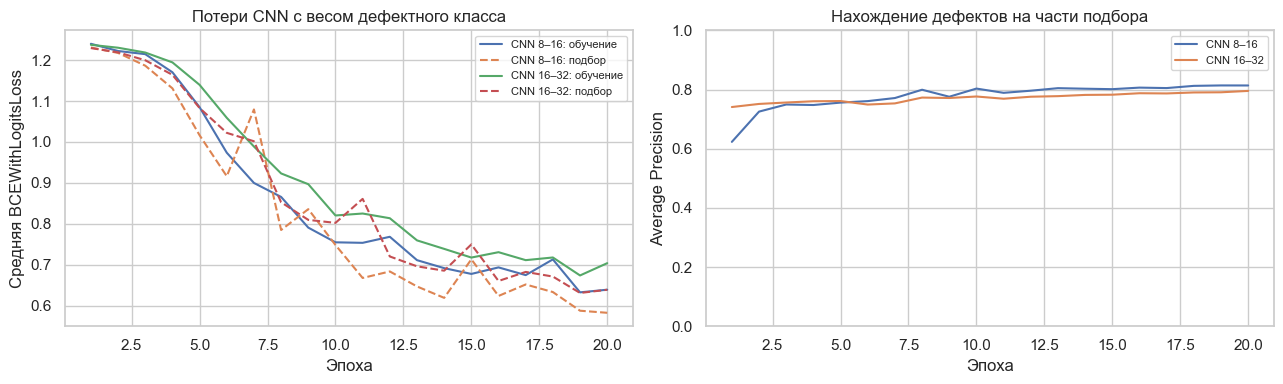

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for config in configs:
    name, history = config['name'], histories[config['name']]
    axes[0].plot(history.epoch, history.train_loss, label=name + ': обучение')
    axes[0].plot(history.epoch, history.valid_loss, '--', label=name + ': подбор')
    axes[1].plot(history.epoch, history.valid_AP, label=name)
axes[0].set(title='Потери CNN с весом дефектного класса', xlabel='Эпоха', ylabel='Средняя BCEWithLogitsLoss')
axes[1].set(title='Нахождение дефектов на части подбора', xlabel='Эпоха', ylabel='Average Precision', ylim=(0, 1))
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
save_show(fig, '02_training_loss_AP.png')

Сплошные линии — обучение, пунктирные — часть подбора. Если потери обучения снижаются, а проверочные растут, возможно переобучение. В этом запуске обе потери в целом уменьшаются. Dropout включён только при обучении, поэтому обучающие потери могут быть выше проверочных. Справа AP: выше значит, что реальные дефекты чаще оказываются в начале списка подозрительных снимков. Лучшая эпоха выбирается по части подбора, поэтому последняя эпоха не обязательно сохраняется.

Показываем норму градиентов всей сети и первой свёртки.

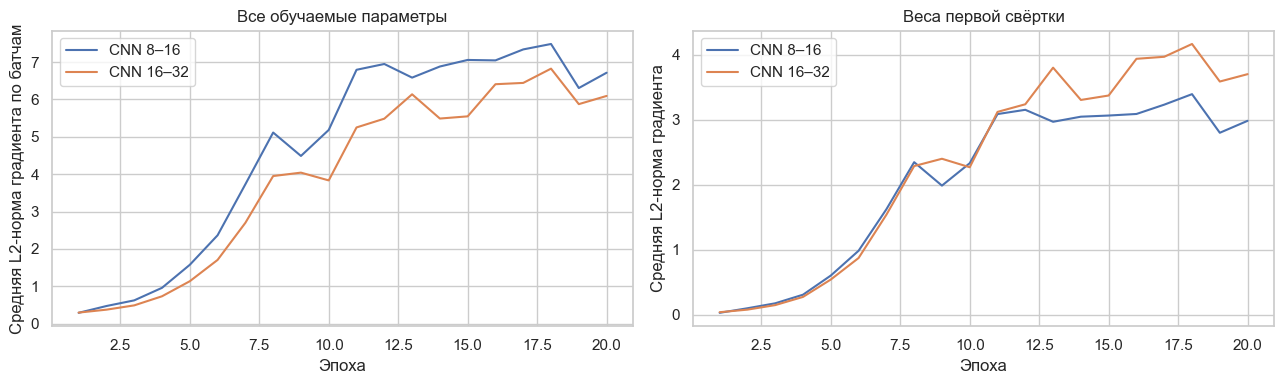

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for config in configs:
    name, history = config['name'], histories[config['name']]
    axes[0].plot(history.epoch, history.gradient_norm, label=name)
    axes[1].plot(history.epoch, history.first_conv_gradient, label=name)
axes[0].set(title='Все обучаемые параметры', xlabel='Эпоха', ylabel='Средняя L2-норма градиента по батчам')
axes[1].set(title='Веса первой свёртки', xlabel='Эпоха', ylabel='Средняя L2-норма градиента')
for ax in axes:
    ax.legend()
fig.tight_layout()
save_show(fig, '03_gradient_norms.png')

Норма показывает величину градиента перед шагом оптимизатора, а не число ошибок. Убывание не обязано быть ровным: батчи содержат разные снимки и разное число редких дефектов. Всплеск нужно рассматривать вместе с потерями. Градиент первой свёртки показывает, доходит ли сигнал обучения до начала сети. Это наблюдения данного запуска, а не универсальный «правильный диапазон» для любой CNN.

В этом запуске нормы в целом увеличиваются, хотя потери снижаются. Поэтому меньшая норма сама по себе не означает более точную сеть. Значения остаются конечными, а у первой свёртки сохраняется ненулевой градиент: сигнал обучения до неё доходит.

Выбираем порог тревоги только по части подбора.

In [20]:
valid_probability, _ = evaluate_cnn(best_model, valid_data)
threshold_rows = []
for threshold in np.linspace(0.05, 0.95, 19):
    predicted = valid_probability >= threshold
    threshold_rows.append({'threshold': threshold,
        'F1': f1_score(labels[valid_idx], predicted, zero_division=0),
        'precision': precision_score(labels[valid_idx], predicted, zero_division=0),
        'recall': recall_score(labels[valid_idx], predicted, zero_division=0)})
threshold_table = pd.DataFrame(threshold_rows)
best_threshold = float(threshold_table.loc[threshold_table.F1.idxmax(), 'threshold'])
display(threshold_table)
print('Порог по максимуму F1 части подбора:', best_threshold)

,threshold,F1,precision,recall
0,0.05,0.189922,0.104925,1.000000
1,0.10,0.189922,0.104925,1.000000
2,0.15,0.223235,0.125641,1.000000
3,0.20,0.325424,0.195122,0.979592
4,0.25,0.410959,0.264706,0.918367
5,0.30,0.511364,0.354331,0.918367
6,0.35,0.579310,0.437500,0.857143
7,0.40,0.626866,0.494118,0.857143
8,0.45,0.634146,0.527027,0.795918
9,0.50,0.660550,0.600000,0.734694


Порог по максимуму F1 части подбора: 0.7999999999999999


По умолчанию можно использовать порог 0,5, но при редких дефектах и весах классов полезно выбрать его отдельно. Здесь максимизируем F1 на заранее заданной сетке порогов; при равенстве берём меньший порог. Цена ложной тревоги и пропущенного дефекта в реальном производстве могла бы потребовать другого правила. Число после sigmoid — оценка дефектности; из-за весов классов оно не обязательно является точной вероятностью события.

### 3.3. Открываем итоговый тест
Архитектура, веса и порог зафиксированы. Теперь оцениваем выбранную CNN на 1004 изображениях теста авторов. Ни её эпоху, ни порог по этому результату не изменяем.

Вычисляем итоговые оценки CNN и простого ответа большинства.

In [21]:
test_probability, test_loss = evaluate_cnn(best_model, test_data)
test_prediction = (test_probability >= best_threshold).astype(int)
actual = labels[test_idx]
def binary_scores(y, probability, predicted):
    return {'accuracy': accuracy_score(y, predicted), 'balanced_accuracy': balanced_accuracy_score(y, predicted),
        'precision': precision_score(y, predicted, zero_division=0), 'recall': recall_score(y, predicted, zero_division=0),
        'F1': f1_score(y, predicted, zero_division=0), 'AP': average_precision_score(y, probability),
        'ROC_AUC': roc_auc_score(y, probability)}
majority_probability = np.zeros(len(actual))
test_table = pd.DataFrame([
    {'model': 'Всегда без дефекта', **binary_scores(actual, majority_probability, np.zeros(len(actual), dtype=int))},
    {'model': best_name, **binary_scores(actual, test_probability, test_prediction)}
])
display(test_table)

,model,accuracy,balanced_accuracy,precision,recall,F1,AP,ROC_AUC
0,Всегда без дефекта,0.890438,0.500000,0.00000,0.000000,0.000000,0.109562,0.500000
1,CNN 8–16,0.939243,0.766575,0.84507,0.545455,0.662983,0.768238,0.921934


Показываем ошибки CNN и ответы на разных порогах.

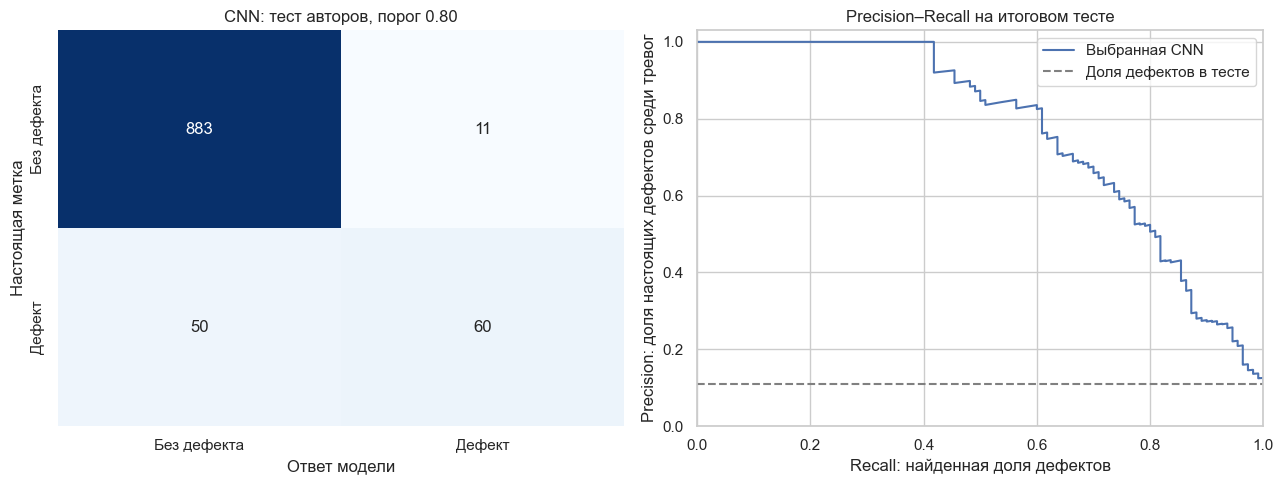

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(confusion_matrix(actual, test_prediction, labels=[0, 1]), annot=True, fmt='d',
            cmap='Blues', cbar=False, xticklabels=['Без дефекта', 'Дефект'],
            yticklabels=['Без дефекта', 'Дефект'], ax=axes[0])
axes[0].set(title=f'CNN: тест авторов, порог {best_threshold:.2f}', xlabel='Ответ модели', ylabel='Настоящая метка')
precision, recall, _ = precision_recall_curve(actual, test_probability)
axes[1].plot(recall, precision, label='Выбранная CNN')
axes[1].axhline(actual.mean(), linestyle='--', color='gray', label='Доля дефектов в тесте')
axes[1].set(title='Precision–Recall на итоговом тесте', xlabel='Recall: найденная доля дефектов',
            ylabel='Precision: доля настоящих дефектов среди тревог', xlim=(0, 1), ylim=(0, 1.03))
axes[1].legend()
fig.tight_layout()
save_show(fig, '04_test_errors_PR.png')

Верхняя правая клетка — ложные тревоги, нижняя левая — пропущенные дефекты. Ответ «всегда без дефекта» не даёт ложных тревог, но пропускает все дефекты; поэтому одной accuracy мало. Справа виден обмен между числом найденных дефектов и чистотой списка тревог. Кривая относится к итоговому тесту и показана для анализа, а рабочий порог уже выбран по другой части.

Сравниваем оценки дефектности для настоящих классов.

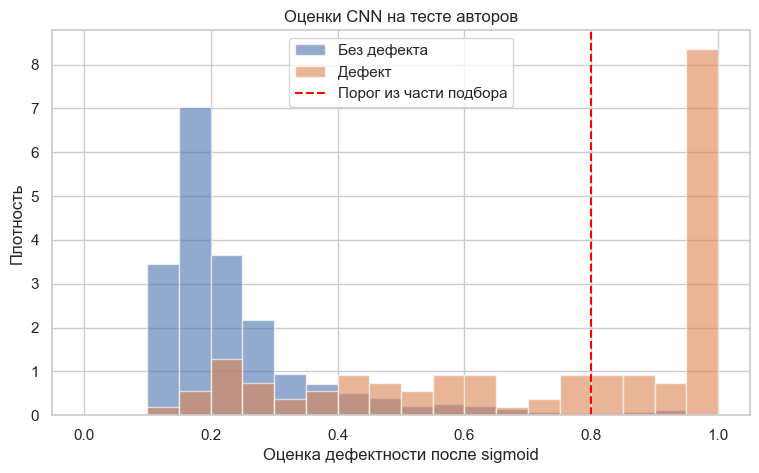

In [23]:
fig, ax = plt.subplots(figsize=(9, 5))
for label, name in [(0, 'Без дефекта'), (1, 'Дефект')]:
    ax.hist(test_probability[actual == label], bins=np.linspace(0, 1, 21), alpha=0.6, density=True, label=name)
ax.axvline(best_threshold, color='red', linestyle='--', label='Порог из части подбора')
ax.set(title='Оценки CNN на тесте авторов', xlabel='Оценка дефектности после sigmoid', ylabel='Плотность')
ax.legend()
save_show(fig, '05_test_scores.png')

Каждая гистограмма нормирована отдельно, чтобы редкий класс был виден. Снимки справа от порога вызывают тревогу. Перекрытие распределений объясняет, почему нельзя одновременно убрать все ложные тревоги и найти все дефекты. Высота здесь — плотность, а не число изображений.

Показываем примеры ошибок и правильно найденных дефектов.

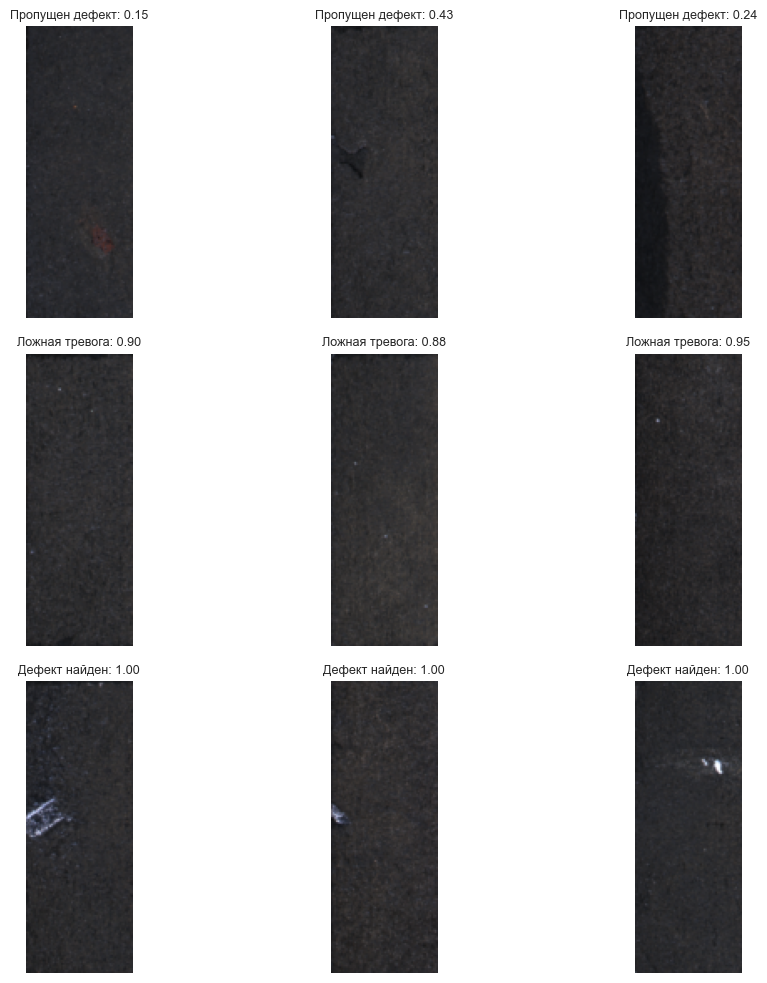

In [24]:
false_negative = np.flatnonzero((actual == 1) & (test_prediction == 0))[:3]
false_positive = np.flatnonzero((actual == 0) & (test_prediction == 1))[:3]
true_positive = np.flatnonzero((actual == 1) & (test_prediction == 1))[:3]
examples = [(i, 'Пропущен дефект') for i in false_negative] + [(i, 'Ложная тревога') for i in false_positive] + [(i, 'Дефект найден') for i in true_positive]
fig, axes = plt.subplots(3, 3, figsize=(11, 10))
for ax in axes.flat:
    ax.axis('off')
for ax, (position, title) in zip(axes.flat, examples):
    index = test_idx[position]
    ax.imshow(images[index])
    ax.set_title(f'{title}: {test_probability[position]:.2f}', fontsize=9)
fig.tight_layout()
save_show(fig, '06_test_examples.png')

Это снимки именно итогового теста. Подпись объясняет тип ответа и оценку модели. Если определённого типа ошибок нет, соответствующие примеры не придумываются, а панели остаются свободными. Изображения показаны в уменьшенном размере, который получила CNN. По ним можно обсуждать трудные случаи, но параметры по этому тесту уже не подбираем.

### 3.4. Сохраняем и локально применяем модель
Этап развёртывания выполняем локально: сохраняем веса, архитектуру, размер входа, классы и порог; затем загружаем файл в новую сеть и распознаём изображение по пути. Веб-сервис и внешняя публикация для этого не нужны.

Сохраняем модель с настройками подготовки и порогом.

In [25]:
checkpoint_path = REPORT / 'surface_cnn.pt'
torch.save({'state_dict': best_model.state_dict(), 'config': best_config, 'image_size': IMAGE_SIZE,
            'threshold': best_threshold, 'classes': ['Без дефекта', 'Дефект']}, checkpoint_path)

Загружаем сохранённые веса в новую сеть.

In [26]:
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
loaded_model = make_cnn(checkpoint['config']['channels'])
loaded_model.load_state_dict(checkpoint['state_dict'])
loaded_model.eval()

Sequential(
  (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): AdaptiveMaxPool2d(output_size=(2, 2))
  (7): Flatten(start_dim=1, end_dim=-1)
  (8): Linear(in_features=64, out_features=32, bias=True)
  (9): ReLU()
  (10): Dropout(p=0.25, inplace=False)
  (11): Linear(in_features=32, out_features=1, bias=True)
)

Определяем применение модели к одному изображению.

In [27]:
def inspect_surface(path):
    with Image.open(path) as image:
        resized = image.convert('RGB').resize(tuple(checkpoint['image_size']), Image.Resampling.BILINEAR)
        tensor = torch.from_numpy(np.asarray(resized).copy()).permute(2, 0, 1).unsqueeze(0).float() / 255
    with torch.no_grad():
        probability = loaded_model(tensor).sigmoid().item()
    predicted = int(probability >= checkpoint['threshold'])
    return {'file': Path(path).name, 'score': probability, 'answer': checkpoint['classes'][predicted]}

Применяем загруженную CNN к двум настоящим тестовым снимкам.

In [28]:
demo_positions = [np.flatnonzero(actual == 0)[0], np.flatnonzero(actual == 1)[0]]
demo_results = [inspect_surface(image_root / image_info.iloc[test_idx[position]].file) for position in demo_positions]
display(pd.DataFrame(demo_results))

,file,score,answer
0,20000.png,0.189703,Без дефекта
1,20042.png,1.000000,Дефект


Сохраняем таблицы, историю градиентов, разбиение и простой текст результата.

In [29]:
validation_table.to_csv(REPORT / 'validation_metrics.csv', index=False)
threshold_table.to_csv(REPORT / 'threshold_validation.csv', index=False)
test_table.to_csv(REPORT / 'test_metrics.csv', index=False)
image_info.to_csv(REPORT / 'images.csv', index=False)
for index, (name, history) in enumerate(histories.items()):
    history.to_csv(REPORT / f'history_{index}.csv', index=False)
pd.DataFrame({'row': test_idx, 'file': image_info.file.iloc[test_idx].to_numpy(), 'actual': actual,
              'score': test_probability, 'prediction': test_prediction}).to_csv(REPORT / 'predictions.csv', index=False)
np.savez_compressed(REPORT / 'split_indices.npz', train=train_idx, valid=valid_idx, test=test_idx)
selected_metrics = test_table.iloc[1]
analysis = (f'Получил практические навыки реализации пайплайна с CNN. Обработал {len(images)} настоящих '
            f'промышленных снимков KolektorSDD2, сохранил тест авторов отдельно. По части подбора выбрана '
            f'{best_name}, эпоха {chosen_epochs[best_name]}, порог {best_threshold:.2f}. '
            f'На {len(test_idx)} итоговых снимках AP = {selected_metrics.AP:.3f}, '
            f'найдено {selected_metrics.recall:.1%} дефектов, precision = {selected_metrics.precision:.1%}. '
            'Изучил потери и нормы градиентов, сохранил и повторно загрузил сеть для локального распознавания. '
            'Это учебная модель на уменьшенных снимках; работа готового промышленного детектора не заявляется.')
display(Markdown(analysis))
(REPORT / 'analysis.md').write_text(analysis, encoding='utf-8')
summary = {'dataset': 'KolektorSDD2', 'cpu_threads': torch.get_num_threads(), 'images': len(images), 'defects': int(labels.sum()),
           'split': [len(train_idx), len(valid_idx), len(test_idx)], 'image_size': IMAGE_SIZE,
           'selected': best_name, 'selected_epoch': chosen_epochs[best_name], 'threshold': best_threshold,
           'validation_metrics': validation_table.to_dict('records'), 'test_metrics': test_table.to_dict('records'),
           'figures': sorted(p.name for p in FIGURES.glob('*.png'))}
(REPORT / 'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
sha = hashlib.file_digest(archive_path.open('rb'), 'sha256').hexdigest()
sources = {'url': source_url, 'description': 'https://www2.vicos.si/resources/kolektorsdd2/',
           'license': 'CC BY-NC-SA 4.0', 'sha256': {str(archive_path.relative_to(ROOT)): sha}}
(REPORT / 'sources.json').write_text(json.dumps(sources, ensure_ascii=False, indent=2), encoding='utf-8')

Получил практические навыки реализации пайплайна с CNN. Обработал 3335 настоящих промышленных снимков KolektorSDD2, сохранил тест авторов отдельно. По части подбора выбрана CNN 8–16, эпоха 19, порог 0.80. На 1004 итоговых снимках AP = 0.768, найдено 54.5% дефектов, precision = 84.5%. Изучил потери и нормы градиентов, сохранил и повторно загрузил сеть для локального распознавания. Это учебная модель на уменьшенных снимках; работа готового промышленного детектора не заявляется.

294

## 4. Заключение
Получил практические навыки по реализации пайплайна для решения задачи машинного обучения с использованием свёрточной нейросетевой модели. Выбрал реальные снимки промышленного мониторинга, подготовил входы, спроектировал CNN из блоков и выполнил обучение с подбором параметров.

Изучил изменение потерь и градиентов, оценил пропущенные дефекты и ложные тревоги на отдельном тесте. Сохранил сеть и применил её после повторной загрузки. Увидел, почему при редких дефектах нужно смотреть на recall, precision и AP вместе с accuracy. Качество зависит от размера снимков, разметки и выбранного порога; низкие потери обучения сами по себе не гарантируют хорошую проверку.

На тесте авторов выбранная CNN нашла 60 из 110 дефектов и дала 11 ложных тревог; 50 дефектов были пропущены. Общая accuracy составила 93,92%, но найдено лишь 54,55% всех дефектов. Поэтому такую учебную модель нельзя считать готовым надёжным детектором только по высокой общей точности. Порог 0,80 был выбран по части подбора и после просмотра теста не менялся.

## 5. Ответы на контрольные вопросы
**1. Чем CNN отличается от MLP?**  
MLP связывает нейрон со всеми входными числами. CNN работает с местными участками изображения и повторно использует один фильтр в разных местах. Она сохраняет пространственное расположение пикселей на первых слоях и обычно требует меньше параметров для изображений.

**2. Что такое глубокие сети и какие слои в них встречаются?**  
Сети с несколькими обучаемыми слоями представлений. Встречаются свёрточные и полносвязные слои, активации, pooling, нормализация и dropout. Не каждый слой имеет веса: ReLU и MaxPool их не обучают.

**3. Что такое свёртка и как задать её в PyTorch?**  
Фильтр проходит по местным участкам и считает взвешенную сумму пикселей. `nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding)` задаёт входные каналы, число фильтров, ядро, шаг и отступ. Для одной стороны при dilation=1 размер выхода равен `floor((input + 2*padding - kernel_size)/stride + 1)`. Поэтому ядро 3, шаг 1 и отступ 1 сохраняют размер. Для произвольной dilation вместо kernel_size используют `dilation*(kernel_size-1)+1`.

**4. Какие слои уменьшают размер карт?**  
`MaxPool2d` оставляет максимум окна, `AvgPool2d` — среднее. `AdaptiveAvgPool2d` и `AdaptiveMaxPool2d` дают заранее заданный размер выхода. В нашей сети MaxPool2d(2) уменьшает высоту и ширину вдвое; число каналов pooling обычно не меняет.

**5. Как задать полносвязный слой?**  
`nn.Linear(in_features, out_features)` вычисляет линейное преобразование со смещением. Перед ним карты обычно разворачивают через `nn.Flatten`; число полученных значений должно совпадать с in_features.

**6. Что такое метод оптимизации?**  
Правило изменения весов по градиентам. В PyTorch есть SGD, Adam, AdamW, RMSprop и другие. Меняют шаг, momentum, размер батча и расписание шага. Градиенты считает `backward()`, обновление выполняет оптимизатор.

**7. Что такое функция потерь и какие варианты есть?**  
Число, которое модель старается уменьшить при обучении. Для классификации используют CrossEntropyLoss, NLLLoss, BCELoss и BCEWithLogitsLoss; для регрессии — MSELoss, L1Loss, SmoothL1Loss. В этой работе бинарный выход обучается BCEWithLogitsLoss без отдельного sigmoid перед потерями.

**8. Как составить последовательность слоёв?**  
`nn.Sequential`. Выход одного слоя должен подходить следующему: число каналов Conv2d, пространственный размер pooling и число входов Linear согласуются. Учебный прямой проход показывает эти размеры на настоящем батче.

**9. Что такое регуляризация и как уменьшить переобучение?**  
Способы меньше запоминать частные особенности обучения: штраф за большие веса, dropout, разумное увеличение разнообразия обучающих изображений, более простая сеть и остановка по отдельной части подбора. Нельзя выбирать параметры по итоговому тесту.

**10. Как выглядят переобучение и недообучение?**  
При переобучении сеть хорошо отвечает на обучении, а проверочные ошибки остаются большими или растут. При недообучении качество слабое и на обучении, и на проверке. Причиной могут быть недостаток возможностей сети, короткое обучение или неподходящие параметры.

## 6. Источники
- Методичка *Practicum_AI_Methods.pdf*, с. 156–160.
- [KolektorSDD2, ViCoS Lab: данные, разбиение и лицензия](https://www2.vicos.si/resources/kolektorsdd2/).
- [Božič, Tabernik, Skočaj, 2021: описание набора](https://arxiv.org/abs/2104.06064).
- [PyTorch: Conv2d](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Conv2d.html).
- [PyTorch: BCEWithLogitsLoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.BCEWithLogitsLoss.html).
- [PyTorch: AdaptiveMaxPool2d](https://docs.pytorch.org/docs/2.14/generated/torch.nn.AdaptiveMaxPool2d.html).